# Chương 4: Knowledge Graph và RAG
**3 bài áp dụng:** Bệnh tiểu đường · Chứng khoán · Vàng, mỗi bài đều có **Knowledge Graph (KG)** và **RAG / GraphRAG**.

| Mục | Nội dung |
|---|---|
| 4.1 | Mở đầu: lịch sử KG và RAG, vai trò với AI |
| 4.2 | Knowledge Graph và Knowledge Base, dữ liệu dùng trong bài |
| 4.3 | RAG và GraphRAG (phần lõi dùng chung) |
| 4.4 | **Bài 1:** KB và RAG cho bệnh tiểu đường |
| 4.5.1 | **Bài 2:** KB và RAG cho chứng khoán |
| 4.5.2 | **Bài 3:** KB và RAG cho vàng |
| 4.6 | Deploy (Gradio + đóng gói `app.py`) |

> **Chạy trên Kaggle:** *Settings → Internet → On* rồi **Run All**. Notebook tự tải dữ liệu; CPU là đủ.

## 4.1 Mở đầu

### 4.1.1 KG và RAG: lịch sử ngắn gọn

**Knowledge Graph (KG)**
- Thập niên 1960: *semantic network* (Quillian) biểu diễn tri thức bằng nút và cạnh.
- 2001: *Semantic Web* (Berners-Lee) với RDF, OWL, SPARQL.
- 2007–2014: DBpedia, Freebase, Wikidata; 2012 Google công bố **Knowledge Graph** ("things, not strings").
- Từ 2015: KG thành hạ tầng cho tìm kiếm, gợi ý, y sinh (UMLS, DrugBank, Hetionet), tài chính.

**RAG (Retrieval-Augmented Generation)**
- 2020: Lewis và cộng sự (Facebook AI) đề xuất RAG: bộ truy xuất (retriever) + mô hình sinh (generator).
- 2022–2023: LLM + vector database (FAISS, Chroma...) làm RAG thành mẫu thiết kế phổ biến.
- 2024: **GraphRAG** (Microsoft và cộng đồng) đưa KG vào RAG để truy xuất theo quan hệ, trả lời câu hỏi nhiều bước (multi-hop).

### 4.1.2 Vai trò đối với AI

| Vấn đề của LLM thuần | KG / RAG giải quyết thế nào |
|---|---|
| Bịa thông tin (hallucination) | Câu trả lời dựa trên tài liệu truy xuất được, có trích nguồn |
| Kiến thức cũ | Chỉ cần cập nhật kho tài liệu, không phải huấn luyện lại |
| Khó giải thích | KG cho thấy đường suy luận (thực thể → quan hệ → thực thể) |
| Câu hỏi nhiều bước | Duyệt đồ thị để nối thông tin nằm ở nhiều tài liệu |
| Dữ liệu chuyên ngành, riêng tư | Dùng kho tri thức nội bộ |

In [1]:
# --- Cài thư viện (Kaggle) ---
!pip install -q biopython yfinance gradio sentence-transformers networkx \
    scikit-learn "huggingface-hub>=1.3,<2"


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, sys, json, glob, shutil, itertools, collections, warnings
import xml.etree.ElementTree as ET
import numpy as np, pandas as pd, networkx as nx, requests
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ON_KAGGLE = os.path.exists("/kaggle/working")
WORK_DIR = os.environ.get("WORK_DIR", "/kaggle/working" if ON_KAGGLE else ".")
DATA_DIR = os.environ.get("LOCAL_DATA", os.path.join(WORK_DIR, "rag_kg_data"))
os.makedirs(DATA_DIR, exist_ok=True)
FIG_DIR = os.path.join(WORK_DIR, "figs")
os.makedirs(FIG_DIR, exist_ok=True)


def save_show(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()


if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
print("DATA_DIR =", DATA_DIR)

DATA_DIR = C:\DATA\KG_RAG\data


## 4.2 Knowledge Graph và Knowledge Base

- **Knowledge Base (KB):** kho tri thức có cấu trúc hoặc bán cấu trúc (bảng, tài liệu đã làm sạch, ontology).
- **Knowledge Graph (KG):** KB biểu diễn dạng đồ thị gồm các bộ ba **(chủ thể, quan hệ, đối tượng)**, ví dụ `(SGLT2 inhibitor) —drug_studied_for→ (Nephropathy)`.

### 4.2.1 Dữ liệu của 3 bài: bảng (table) và văn bản (text)

| Bài | Dữ liệu **văn bản** (text) | Dữ liệu **bảng** (table) | Nguồn |
|---|---|---|---|
| Tiểu đường | ~300 abstract bài báo y khoa | Nhãn MeSH của từng bài | PubMed (NCBI E-utilities) |
| Chứng khoán | Mô tả công ty + tin tức (tiêu đề) | Giá hằng ngày VNM, FPT, VCB, HPG, VIC từ 2020; ngành, lĩnh vực | yfinance, Google News RSS |
| Vàng | Tin tức về vàng (tiêu đề) | Giá vàng + các yếu tố: USD index, lợi suất TP Mỹ 10 năm, bạc, dầu, S&P 500, VIX, Bitcoin | yfinance, Google News RSS |

**Bảng không đưa thẳng vào RAG được** (RAG truy xuất văn bản), nên bài chuyển bảng thành câu văn: thống kê theo năm (lợi suất, biến động, sụt giảm tối đa) và tương quan giữa các tài sản. Bảng cũng là nguồn trực tiếp để dựng **cạnh tương quan** trong KG.

### 4.2.2 Quy trình xây dựng KG (cả 3 bài)
1. **Chuẩn bị KB:** làm sạch, chia văn bản thành chunk; chuyển bảng thành câu văn.
2. **Nhận diện thực thể (NER):** từ điển (lexicon) + regex, dễ kiểm soát, không cần API.
3. **Trích quan hệ:**
   - từ **văn bản**: hai thực thể cùng xuất hiện trong một chunk/tin → cạnh, trọng số = số lần đồng xuất hiện, loại quan hệ suy ra từ kiểu thực thể;
   - từ **bảng**: hệ số tương quan lợi suất → cạnh `CORRELATED_WITH`; thuộc tính công ty → `BELONGS_TO_SECTOR`;
   - từ **tri thức chuyên gia** (bài vàng): vài quan hệ nhân quả đã biết, đánh dấu `source=domain`.
4. **Lưu trữ:** `networkx`, export GraphML (nạp được vào Neo4j).

In [3]:
PUBMED_FILE = "diabetes_pubmed.jsonl"
STOCKS = {
    "VNM": "VNM.VN",
    "FPT": "FPT.VN",
    "VCB": "VCB.VN",
    "HPG": "HPG.VN",
    "VIC": "VIC.VN",
}
GOLD_MKT = {
    "GOLD": "GC=F",
    "SILVER": "SI=F",
    "USD": "DX-Y.NYB",
    "US10Y": "^TNX",
    "OIL": "CL=F",
    "SP500": "^GSPC",
    "VIX": "^VIX",
    "BTC": "BTC-USD",
}
STOCK_NEWS_Q = [
    "Vinamilk",
    "FPT Corporation",
    "Vietcombank",
    "Hoa Phat Group",
    "Vingroup",
    "VN-Index Vietnam stock market",
]
GOLD_NEWS_Q = [
    "gold price",
    "gold Federal Reserve interest rates",
    "central banks buying gold",
    "gold inflation dollar",
    "gold safe haven geopolitical",
    "gold ETF inflows",
    "gold demand China India",
]
H = {"User-Agent": "Mozilla/5.0"}


def fetch_pubmed(path, n=300):
    from Bio import Entrez

    Entrez.email = "student@example.com"
    q = (
        "(diabetes mellitus[MeSH Terms]) AND (treatment OR complications OR diagnosis) "
        "AND hasabstract AND English[lang]"
    )
    ids = Entrez.read(Entrez.esearch(db="pubmed", term=q, retmax=n, sort="relevance"))[
        "IdList"
    ]
    recs = []
    for i in range(0, len(ids), 100):
        xml = Entrez.read(
            Entrez.efetch(db="pubmed", id=",".join(ids[i : i + 100]), retmode="xml")
        )
        for art in xml["PubmedArticle"]:
            c = art["MedlineCitation"]
            a = c["Article"]
            ab = " ".join(str(t) for t in a.get("Abstract", {}).get("AbstractText", []))
            mesh = [str(m["DescriptorName"]) for m in c.get("MeshHeadingList", [])]
            recs.append(
                {
                    "pmid": str(c["PMID"]),
                    "title": str(a["ArticleTitle"]),
                    "abstract": ab,
                    "mesh": mesh,
                }
            )
    with open(path, "w", encoding="utf-8") as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")


def fetch_prices(symbols, path):
    import yfinance as yf

    out = {}
    for name, sym in symbols.items():
        df = yf.download(sym, start="2020-01-01", progress=False, auto_adjust=True)
        df.columns = [c[0] if isinstance(c, tuple) else c for c in df.columns]
        out[name] = df["Close"]
    pd.DataFrame(out).to_csv(path)


def fetch_company_info(path):
    import yfinance as yf

    info = {}
    for name, sym in STOCKS.items():
        try:
            i = yf.Ticker(sym).info
            info[name] = {
                k: i.get(k)
                for k in [
                    "longName",
                    "sector",
                    "industry",
                    "country",
                    "longBusinessSummary",
                ]
            }
        except Exception as e:
            info[name] = {"error": str(e)}
    json.dump(info, open(path, "w", encoding="utf-8"), ensure_ascii=False, indent=2)


def fetch_news(queries, path):
    rows = []
    for q in queries:
        r = requests.get(
            "https://news.google.com/rss/search",
            headers=H,
            timeout=30,
            params={"q": q, "hl": "en-US", "gl": "US", "ceid": "US:en"},
        )
        for it in ET.fromstring(r.content).findall(".//item"):
            src = it.find("source")
            rows.append(
                {
                    "query": q,
                    "title": (it.findtext("title") or "").rsplit(" - ", 1)[0],
                    "source": src.text if src is not None else "",
                    "date": it.findtext("pubDate"),
                    "link": it.findtext("link"),
                }
            )
    pd.DataFrame(rows).drop_duplicates("title").to_csv(path, index=False)


FILES = {
    PUBMED_FILE: lambda p: fetch_pubmed(p),
    "stock_prices.csv": lambda p: fetch_prices(STOCKS, p),
    "company_info.json": fetch_company_info,
    "stock_news.csv": lambda p: fetch_news(STOCK_NEWS_Q, p),
    "gold_market.csv": lambda p: fetch_prices(GOLD_MKT, p),
    "gold_news.csv": lambda p: fetch_news(GOLD_NEWS_Q, p),
}
for fn, fetch in FILES.items():
    dst = os.path.join(DATA_DIR, fn)
    if os.path.exists(dst):
        continue
    hits = glob.glob(
        f"/kaggle/input/**/{fn}", recursive=True
    )  # ưu tiên file đã upload thành Kaggle Dataset
    if hits:
        shutil.copy(hits[0], dst)
    else:
        print("Đang tải", fn)
        fetch(dst)
for fn in FILES:
    print(f"{fn:22s} {os.path.getsize(os.path.join(DATA_DIR, fn))/1024:8.1f} KB")

diabetes_pubmed.jsonl     548.7 KB
stock_prices.csv          133.1 KB
company_info.json           8.6 KB
stock_news.csv            240.9 KB
gold_market.csv           272.6 KB
gold_news.csv             281.2 KB


## 4.3 RAG và GraphRAG

Pipeline dùng chung cho cả 3 bài:

```
câu hỏi ──► [nhận diện thực thể] ──► mở rộng bằng láng giềng trong KG
   │                                          │
   └──► [embedding + TF-IDF] ──► điểm vector ─┴─► điểm = vector + α·(thực thể khớp) + β·(láng giềng khớp)
                                                      │
                                      top-k tài liệu ──► câu trả lời trích xuất + nguồn + facts từ KG
```

- **Điểm vector (hybrid):** cosine embedding (`all-MiniLM-L6-v2`) + 0.5 × cosine TF-IDF (bắt tốt mã cổ phiếu, năm, con số). Không có sentence-transformers thì chỉ dùng TF-IDF.
- **RAG thường:** chỉ dùng điểm vector.
- **GraphRAG:** cộng điểm cho tài liệu chứa thực thể của câu hỏi và thực thể láng giềng trong KG (bỏ các "hub" quá phổ biến) và trả kèm **facts từ KG**.
- **Sinh câu trả lời:** mặc định *trích xuất* câu liên quan nhất kèm nguồn (không cần API key); có ô tùy chọn dùng LLM.

Phần lõi được ghi ra `ragkg_core.py` để dùng lại khi deploy.

In [4]:
%%writefile ragkg_core.py
import re, json, itertools, collections
import numpy as np
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer

STOP = set(
    "the and for are was were with that this from what which how does did who "
    "whom into than then have has had its their about between over under after "
    "before while there any".split()
)


def split_sentences(t):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", t) if s.strip()]


def chunk_text(title, text, n=3):
    sents = split_sentences(text)
    return [f"{title}. " + " ".join(sents[i : i + n]) for i in range(0, len(sents), n)]


def compile_lexicon(lex):
    return {k: re.compile(v[1], re.I) for k, v in lex.items()}


def extract_entities(text, rx):
    return sorted(k for k, r in rx.items() if r.search(text))


def make_rel(table):
    def rel(t1, t2):
        return table.get((t1, t2)) or table.get((t2, t1)) or "related"

    return rel


def new_kg(lex):
    G = nx.Graph()
    for name, (t, _) in lex.items():
        G.add_node(name, kind="entity", etype=t)
    return G


def add_cooccurrence(G, docs, rel, skip_types=("Year",), doc_key=None, doc_kind="doc"):
    """Quan hệ từ văn bản: 2 thực thể cùng xuất hiện trong 1 tài liệu -> 1 cạnh.

    Trọng số cạnh = số tài liệu mà hai thực thể cùng xuất hiện."""
    for d in docs:
        ents = [e for e in d["entities"] if G.nodes[e]["etype"] not in skip_types]
        if doc_key:
            dn = d[doc_key]
            if dn not in G:
                G.add_node(dn, kind=doc_kind)
            for e in ents:
                G.add_edge(dn, e, rel="MENTIONS", weight=1)
        for a, b in itertools.combinations(ents, 2):
            if G.has_edge(a, b):
                G[a][b]["weight"] += 1
            else:
                G.add_edge(
                    a,
                    b,
                    rel=rel(G.nodes[a]["etype"], G.nodes[b]["etype"]),
                    weight=1,
                    source="text",
                )
    return G


def graph_to_dict(G):
    return {
        "nodes": [[n, dict(a)] for n, a in G.nodes(data=True)],
        "edges": [[u, v, dict(a)] for u, v, a in G.edges(data=True)],
    }


def graph_from_dict(d):
    G = nx.Graph()
    G.add_nodes_from((n, a) for n, a in d["nodes"])
    G.add_edges_from((u, v, a) for u, v, a in d["edges"])
    return G


class Retriever:
    """Hybrid: embedding (sentence-transformers) + TF-IDF.

    Không cài được sentence-transformers thì chỉ dùng TF-IDF."""

    def __init__(self, texts, use_embeddings=True, model_name="all-MiniLM-L6-v2"):
        self.texts, self.mode = texts, "tfidf"
        if use_embeddings:
            try:
                from sentence_transformers import SentenceTransformer

                try:
                    from transformers.utils import logging as hf_log

                    hf_log.disable_progress_bar()
                    hf_log.set_verbosity_error()
                except Exception:
                    pass
                self.model = SentenceTransformer(model_name)
                self.emb = self.model.encode(
                    texts,
                    normalize_embeddings=True,
                    batch_size=64,
                    show_progress_bar=False,
                )
                self.mode = "hybrid"
            except Exception as e:
                print(
                    "Không dùng được embedding, chuyển sang TF-IDF:", type(e).__name__
                )
        self.vec = TfidfVectorizer(
            stop_words="english", ngram_range=(1, 2), sublinear_tf=True
        )
        self.tfidf = self.vec.fit_transform(texts)

    def scores(self, q):
        lex = (self.tfidf @ self.vec.transform([q]).T).toarray().ravel()
        if self.mode == "hybrid":
            return (
                self.emb @ self.model.encode([q], normalize_embeddings=True)[0]
                + 0.5 * lex
            )
        return lex


class GraphRAG:
    """RAG thường (mode='rag') hoặc RAG + KG (mode='graph')."""

    def __init__(self, docs, lex, G, retriever, hub_ratio=0.3):
        self.docs, self.G, self.ret = docs, G, retriever
        self.rx = compile_lexicon(lex)
        freq = collections.Counter(e for d in docs for e in d["entities"])
        self.hubs = {e for e, c in freq.items() if c / len(docs) > hub_ratio}

    def entities(self, text):
        return extract_entities(text, self.rx)

    def _ent_neighbors(self, e):
        return [
            (nb, d)
            for nb, d in self.G[e].items()
            if self.G.nodes[nb].get("kind") == "entity"
        ]

    def neighbors(self, ents, topn=4):
        cand = collections.Counter()
        for e in ents:
            if e not in self.G:
                continue
            for nb, d in self._ent_neighbors(e):
                if nb not in ents and nb not in self.hubs:
                    cand[nb] += d.get("weight", 1)
        return [n for n, _ in cand.most_common(topn)]

    def facts(self, ents, per_entity=4):
        out = []
        for e in ents:
            if e not in self.G:
                continue
            for nb, d in sorted(
                self._ent_neighbors(e), key=lambda x: -x[1].get("weight", 1)
            )[:per_entity]:
                extra = f", corr={d['corr']:+.2f}" if "corr" in d else ""
                rel, w = d.get("rel", "related"), d.get("weight", 1)
                out.append(f"({e}) -[{rel}, w={w:.1f}{extra}]-> ({nb})")
        return out

    def retrieve(self, q, k=4, mode="graph", alpha=0.10, beta=0.04):
        s = np.array(self.ret.scores(q), dtype=float)
        qe = self.entities(q)
        nb = self.neighbors(qe) if mode == "graph" else []
        if mode == "graph":
            for i, d in enumerate(self.docs):
                de = set(d["entities"])
                s[i] += alpha * len(de & set(qe)) + beta * len(de & set(nb))
        idx = np.argsort(-s)[:k]
        return (
            [
                {
                    "i": int(i),
                    "score": float(s[i]),
                    "entities": self.docs[i]["entities"],
                }
                for i in idx
            ],
            qe,
            nb,
        )

    def answer(self, q, k=4, mode="graph", n_sent=3):
        hits, qe, nb = self.retrieve(q, k, mode)
        qw = set(re.findall(r"[a-z0-9\-]{3,}", q.lower())) - STOP
        cands, seen = [], set()
        for h in hits:
            for sent in split_sentences(self.docs[h["i"]]["text"]):
                if sent in seen:
                    continue
                seen.add(sent)
                ov = len(qw & set(re.findall(r"[a-z0-9\-]{3,}", sent.lower())))
                cands.append(
                    (ov, h["score"], sent, self.docs[h["i"]].get("source", ""))
                )
        cands.sort(key=lambda x: (-x[0], -x[1]))
        top = cands[:n_sent]
        return {
            "answer": " ".join(c[2] for c in top),
            "sources": sorted({c[3] for c in top if c[3]}),
            "query_entities": qe,
            "graph_expansion": nb,
            "kg_facts": self.facts(qe) if mode == "graph" else [],
            "hits": hits,
        }


def context_recall(rag, questions, k=4, mode="graph"):
    """Tỉ lệ câu hỏi mà top-k ngữ cảnh chứa đủ mọi từ khóa vàng (regex)."""
    ok = []
    for q, gold in questions:
        hits, _, _ = rag.retrieve(q, k, mode)
        ctx = " ".join(rag.docs[h["i"]]["text"] for h in hits).lower()
        ok.append(all(re.search(g, ctx) for g in gold))
    return float(np.mean(ok)), ok

Overwriting ragkg_core.py


In [5]:
from ragkg_core import *

COLORS = ["#4C9BE8", "#E8704C", "#5CB85C", "#E8B84C", "#B07CC6", "#8C8C8C", "#D46A9F"]


def draw_entity_graph(G, title, fname, min_w=1, figsize=(11, 8)):
    H = G.subgraph(
        [n for n, a in G.nodes(data=True) if a.get("kind") == "entity"]
    ).copy()
    H.remove_edges_from(
        [(u, v) for u, v, a in H.edges(data=True) if a.get("weight", 1) < min_w]
    )
    H.remove_nodes_from(list(nx.isolates(H)))
    types = sorted({H.nodes[n]["etype"] for n in H})
    cmap = dict(zip(types, COLORS))
    plt.figure(figsize=figsize)
    pos = nx.spring_layout(H, seed=7, k=1.3)
    wmax = max(a.get("weight", 1) for _, _, a in H.edges(data=True))
    styles = [
        "dashed" if a.get("source") == "domain" else "solid"
        for _, _, a in H.edges(data=True)
    ]
    nx.draw_networkx_edges(
        H,
        pos,
        width=[0.5 + 4 * a.get("weight", 1) / wmax for _, _, a in H.edges(data=True)],
        style=styles,
        alpha=0.45,
    )
    nx.draw_networkx_nodes(
        H, pos, node_color=[cmap[H.nodes[n]["etype"]] for n in H], node_size=900
    )
    nx.draw_networkx_labels(H, pos, font_size=8)
    for t in types:
        plt.scatter([], [], c=cmap[t], label=t)
    plt.legend()
    plt.title(title)
    plt.axis("off")
    save_show(fname)


def show(res):
    print(
        "Thực thể trong câu hỏi:",
        res["query_entities"],
        "| mở rộng KG:",
        res["graph_expansion"],
    )
    for f in res["kg_facts"][:6]:
        print("  KG:", f)
    print("Trả lời:", res["answer"][:700])
    print("Nguồn:", res["sources"], "\n")


def compare(rag, q):
    print("=== RAG thường ===")
    show(rag.answer(q, mode="rag"))
    print("=== GraphRAG ===")
    show(rag.answer(q, mode="graph"))


def evaluate(rag, qa, title, fname):
    rows = []
    for k in (2, 4, 6):
        r1, _ = context_recall(rag, qa, k, "rag")
        r2, _ = context_recall(rag, qa, k, "graph")
        rows.append({"k": k, "RAG": round(r1, 3), "GraphRAG": round(r2, 3)})
    res = pd.DataFrame(rows).set_index("k")
    display(res)
    res.plot.bar(rot=0, figsize=(5, 3), title=f"Context recall@k ({title})")
    plt.ylim(0, 1.05)
    save_show(fname)
    return res


# --- Chuyển BẢNG thành VĂN BẢN (dùng cho chứng khoán và vàng) ---
def yearly_stats(px, level_cols=()):
    rows = []
    for t in px.columns:
        s = px[t].dropna()
        for y, g in s.groupby(s.index.year):
            if len(g) < 30:
                continue
            r = {
                "asset": t,
                "year": y,
                "start": g.iloc[0],
                "last": g.iloc[-1],
                "high": g.max(),
                "low": g.min(),
            }
            if t not in level_cols:
                r.update(
                    {
                        "return": g.iloc[-1] / g.iloc[0] - 1,
                        "vol": g.pct_change().std() * np.sqrt(252),
                        "mdd": (g / g.cummax() - 1).min(),
                    }
                )
            rows.append(r)
    return pd.DataFrame(rows)


def weekly_changes(px, level_cols=()):
    w = px.resample("W").last()
    ch = w.pct_change(fill_method=None)
    for c in level_cols:
        ch[c] = w[c].diff()  # lợi suất / VIX: dùng chênh lệch mức, không dùng %
    return ch


def stats_to_text(r, label, level_cols=()):
    if r.asset in level_cols:
        return (
            f"{r.asset} ({label}) in {r.year}: started at {r.start:.2f}, "
            f"ended at {r['last']:.2f}, ranged from {r.low:.2f} to {r.high:.2f}."
        )
    return (
        f"{r.asset} ({label}) in {r.year}: price return {r['return']:+.1%}, "
        f"annualized volatility {r.vol:.1%}, maximum drawdown {r.mdd:.1%}, "
        f"last price {r['last']:.2f}."
    )


def corr_text(a, b, c):
    s = "strong" if abs(c) > 0.5 else "moderate" if abs(c) > 0.3 else "weak"
    sign = "positive" if c > 0 else "negative"
    return (
        f"Weekly return correlation between {a} and {b} is {c:+.2f} "
        f"({s} {sign} relationship)."
    )


def news_docs(df, rx):
    return [
        {
            "text": f"{str(r.date)[:16]}: {r.title} (source: {r.source}).",
            "source": f"news:{i}",
            "entities": extract_entities(r.title, rx),
        }
        for i, r in df.reset_index(drop=True).iterrows()
    ]

## 4.4 Bài 1: KB và RAG cho bệnh tiểu đường

**Dữ liệu:** văn bản (abstract PubMed) + nhãn MeSH.

### 4.4.1 Knowledge Base
Chia mỗi abstract thành chunk 3 câu (kèm tiêu đề), gắn thực thể thuộc 3 loại: **Drug**, **Complication**, **Disease**.

In [6]:
papers = [
    json.loads(l) for l in open(os.path.join(DATA_DIR, PUBMED_FILE), encoding="utf-8")
]
papers = [p for p in papers if p["abstract"]]
print(len(papers), "bài báo; ví dụ:", papers[0]["title"][:80])
print(
    "MeSH phổ biến:",
    collections.Counter(m for p in papers for m in p["mesh"]).most_common(6),
)

DIAB_LEX = {
    "Metformin": ["Drug", r"metformin"],
    "Insulin": ["Drug", r"\binsulin"],
    "Sulfonylurea": ["Drug", r"sulfonylurea|glibenclamide|glimepiride|gliclazide"],
    "GLP-1 RA": [
        "Drug",
        r"glp-1|glucagon-like peptide|semaglutide|liraglutide"
        r"|dulaglutide|exenatide|tirzepatide",
    ],
    "SGLT2 inhibitor": [
        "Drug",
        r"sglt-?2|empagliflozin|dapagliflozin|canagliflozin|gliflozin",
    ],
    "DPP-4 inhibitor": ["Drug", r"dpp-?4|sitagliptin|linagliptin|saxagliptin|gliptin"],
    "Pioglitazone": ["Drug", r"pioglitazone|thiazolidinedione"],
    "Statin": ["Drug", r"\bstatins?\b|atorvastatin|rosuvastatin|simvastatin"],
    "Retinopathy": ["Complication", r"retinopath|macular edema"],
    "Nephropathy": [
        "Complication",
        r"nephropath|diabetic kidney disease"
        r"|chronic kidney disease|\bckd\b|albuminuria",
    ],
    "Neuropathy": ["Complication", r"neuropath"],
    "Cardiovascular disease": [
        "Complication",
        r"cardiovascular|heart failure|myocardial|coronary|atheroscler",
    ],
    "Stroke": ["Complication", r"stroke"],
    "Foot ulcer": ["Complication", r"foot ulcer|diabetic foot|amputation"],
    "Hypoglycemia": ["Complication", r"hypoglyc"],
    "Ketoacidosis": ["Complication", r"ketoacidosis|\bdka\b"],
    "Type 1 diabetes": ["Disease", r"type 1 diabetes|\bt1d\b|type 1 dm"],
    "Type 2 diabetes": [
        "Disease",
        r"type 2 diabetes|\bt2d\b|\bt2dm\b|type 2 dm"
        r"|đái tháo đường type 2|tiểu đường type 2",
    ],
    "Gestational diabetes": [
        "Disease",
        r"gestational diabetes|\bgdm\b|tiểu đường thai kỳ",
    ],
    "Obesity": ["Disease", r"obesity|overweight|weight loss|béo phì"],
    "Hypertension": ["Disease", r"hypertension|blood pressure|tăng huyết áp"],
}
diab_rx = compile_lexicon(DIAB_LEX)
diab_docs = [
    {
        "text": ch,
        "source": f"PMID:{p['pmid']}",
        "pmid": "PMID:" + p["pmid"],
        "entities": extract_entities(ch, diab_rx),
    }
    for p in papers
    for ch in chunk_text(p["title"], p["abstract"])
]
print(
    len(diab_docs),
    "chunk; trung bình",
    round(np.mean([len(d["entities"]) for d in diab_docs]), 2),
    "thực thể/chunk",
)

298 bài báo; ví dụ: Granuloma Annulare: An Updated Review of Epidemiology, Pathogenesis, and Treatme
MeSH phổ biến: [('Humans', 297), ('Female', 165), ('Male', 146), ('Treatment Outcome', 137), ('Middle Aged', 117), ('Adult', 91)]


1108 chunk; trung bình 0.82 thực thể/chunk


### 4.4.2 Knowledge Graph
Nút: thực thể + bài báo. Cạnh: `MENTIONS` (bài báo → thực thể) và quan hệ thực thể–thực thể theo kiểu: `drug_studied_for`, `drug_used_in`, `complication_of`, `co_used_with`, `comorbid_with`.

Nút: 319 | cạnh: 498 | thực thể: 21


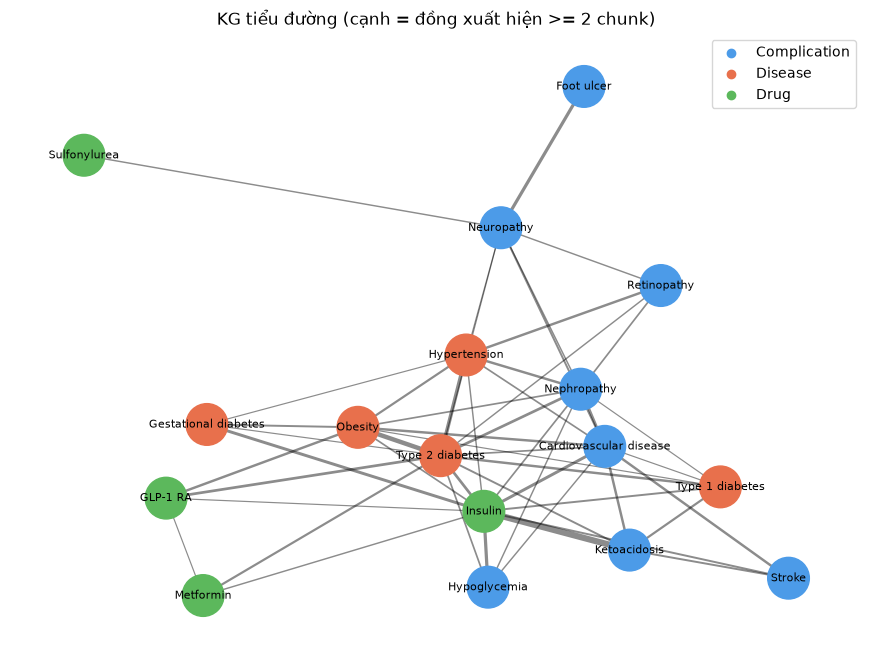

Thuốc nghiên cứu cùng Nephropathy: [('Insulin', 4, 'drug_studied_for'), ('GLP-1 RA', 1, 'drug_studied_for'), ('SGLT2 inhibitor', 1, 'drug_studied_for')]
Bệnh/yếu tố đi cùng GLP-1 RA: [('Type 2 diabetes', 8, 'drug_used_in'), ('Obesity', 7, 'drug_used_in'), ('Type 1 diabetes', 1, 'drug_used_in')]


In [7]:
diab_rel = make_rel(
    {
        ("Complication", "Drug"): "drug_studied_for",
        ("Disease", "Drug"): "drug_used_in",
        ("Complication", "Disease"): "complication_of",
        ("Drug", "Drug"): "co_used_with",
        ("Complication", "Complication"): "comorbid_with",
        ("Disease", "Disease"): "comorbid_with",
    }
)
G_diab = add_cooccurrence(
    new_kg(DIAB_LEX), diab_docs, diab_rel, doc_key="pmid", doc_kind="paper"
)
n_ent = sum(1 for _, a in G_diab.nodes(data=True) if a["kind"] == "entity")
print(
    "Nút:",
    G_diab.number_of_nodes(),
    "| cạnh:",
    G_diab.number_of_edges(),
    "| thực thể:",
    n_ent,
)
nx.write_graphml(G_diab, os.path.join(WORK_DIR, "kg_diabetes.graphml"))
draw_entity_graph(
    G_diab, "KG tiểu đường (cạnh = đồng xuất hiện >= 2 chunk)", "kg_diabetes", min_w=2
)


def top_links(G, node, etype=None, n=5):
    nbs = [
        (nb, d["weight"], d["rel"])
        for nb, d in G[node].items()
        if G.nodes[nb].get("kind") == "entity"
        and (etype is None or G.nodes[nb]["etype"] == etype)
    ]
    return sorted(nbs, key=lambda x: -x[1])[:n]


print("Thuốc nghiên cứu cùng Nephropathy:", top_links(G_diab, "Nephropathy", "Drug"))
print("Bệnh/yếu tố đi cùng GLP-1 RA:", top_links(G_diab, "GLP-1 RA", "Disease"))

### 4.4.3 RAG vs GraphRAG
Đánh giá bằng **context recall@k**: câu hỏi tính là đúng nếu top-k tài liệu truy xuất được chứa **đủ** các từ khóa vàng.

Retriever: hybrid | hub: set()
=== RAG thường ===
Thực thể trong câu hỏi: ['Cardiovascular disease', 'Nephropathy'] | mở rộng KG: []
Trả lời: A thorough therapeutic approach, in both the early and later stages of diabetic nephropathy, is fundamental because of the increased risk of morbidity and mortality. Finally, the manipulation of the sex hormone balance, genetic screening for a predisposition to progressive renal dysfunction and, eventually, gene therapy complete the scenario for future approaches to this major complication of diabetic disease. A low glomerular filtration rate (<60 mL/min/1.73 m(2)) is also an independent risk factor for cardiovascular events and death.
Nguồn: ['PMID:14696750', 'PMID:21531886'] 

=== GraphRAG ===
Thực thể trong câu hỏi: ['Cardiovascular disease', 'Nephropathy'] | mở rộng KG: ['Insulin', 'Type 2 diabetes', 'Hypertension', 'Obesity']
  KG: (Cardiovascular disease) -[drug_studied_for, w=9.0]-> (Insulin)
  KG: (Cardiovascular disease) -[comorbid_with,

,RAG,GraphRAG
k,,
2,0.417,0.750
4,0.667,0.833
6,0.667,0.833


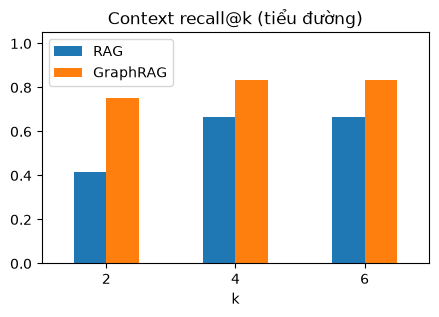

In [8]:
diab_rag = GraphRAG(
    diab_docs, DIAB_LEX, G_diab, Retriever([d["text"] for d in diab_docs])
)
print("Retriever:", diab_rag.ret.mode, "| hub:", diab_rag.hubs)
compare(
    diab_rag,
    "Which drugs are studied for diabetic kidney disease "
    "and do they reduce cardiovascular risk?",
)

DIAB_QA = [
    ("What are the first-line medications for type 2 diabetes?", [r"metformin"]),
    (
        "How do SGLT2 inhibitors affect kidney disease in diabetes?",
        [r"sglt|gliflozin", r"kidney|nephro"],
    ),
    (
        "Which treatments reduce cardiovascular risk in type 2 diabetes?",
        [r"cardiovascular", r"glp-1|sglt|gliflozin|semaglutide"],
    ),
    (
        "Which complications of diabetes affect the eyes and nerves?",
        [r"retinopath", r"neuropath"],
    ),
    ("How is gestational diabetes diagnosed and treated?", [r"gestational"]),
    (
        "What is the role of insulin therapy in type 1 diabetes?",
        [r"insulin", r"type 1"],
    ),
    (
        "Do GLP-1 receptor agonists help weight loss in obesity with diabetes?",
        [r"glp-1|semaglutide|liraglutide", r"obes|weight"],
    ),
    (
        "What is the risk of hypoglycemia with sulfonylureas or insulin?",
        [r"hypoglyc", r"sulfonylurea|insulin"],
    ),
    ("How are diabetic foot ulcers managed?", [r"foot"]),
    (
        "What is the link between hypertension and diabetic nephropathy?",
        [r"hypertension|blood pressure", r"nephropath|kidney"],
    ),
    (
        "Do statins or SGLT2 inhibitors lower stroke and heart failure risk?",
        [r"statin|sglt|gliflozin", r"stroke|heart failure"],
    ),
    (
        "Can metformin be combined with insulin or GLP-1 agonists?",
        [r"metformin", r"insulin|glp-1"],
    ),
]
res_diab = evaluate(diab_rag, DIAB_QA, "tiểu đường", "eval_diabetes")

## 4.5.1 Bài 2: KB và RAG cho chứng khoán

**Dữ liệu:** bảng giá hằng ngày 5 cổ phiếu VN + thông tin công ty (bảng) và mô tả công ty + tin tức (văn bản).

KB gồm 4 loại tài liệu: hồ sơ công ty, thống kê theo năm (từ bảng), tương quan (từ bảng), tin tức.
KG: `Company —BELONGS_TO_SECTOR→ Sector`, `Company —CORRELATED_WITH→ Company` (từ bảng), `Company —in_news_with→ Topic` (từ tin tức).

> Bài minh họa kỹ thuật, **không phải khuyến nghị đầu tư**.

Bảng giá: (1771, 5) 2020-01-01 -> 2026-10-15 | tin tức: 579


asset,FPT,HPG,VCB,VIC,VNM
year,,,,,
2020,0.213,1.156,0.091,-0.059,0.153
2021,0.848,0.527,0.038,-0.011,-0.175
2022,0.015,-0.485,0.015,-0.434,-0.057
2023,0.473,0.553,0.185,-0.171,-0.075
2024,0.852,0.049,0.136,-0.091,-0.009
2025,-0.264,0.189,-0.370,7.365,0.051
2026,-0.325,-0.120,-0.009,0.285,-0.035


,VNM,FPT,VCB,HPG,VIC
VNM,1.00,0.41,0.38,0.32,0.10
FPT,0.41,1.00,0.39,0.43,0.07
VCB,0.38,0.39,1.00,0.43,0.10
HPG,0.32,0.43,0.43,1.00,0.22
VIC,0.10,0.07,0.10,0.22,1.00


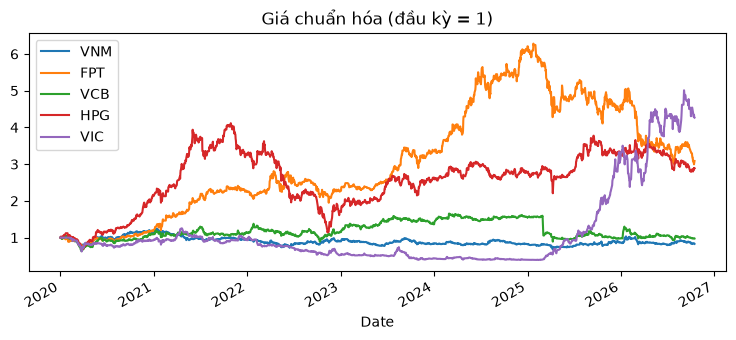

In [9]:
sp = pd.read_csv(
    os.path.join(DATA_DIR, "stock_prices.csv"), parse_dates=[0], index_col=0
).sort_index()
info = json.load(open(os.path.join(DATA_DIR, "company_info.json"), encoding="utf-8"))
info = {k.split(".")[0]: v for k, v in info.items()}  # "VNM.VN" -> "VNM"
snews = pd.read_csv(os.path.join(DATA_DIR, "stock_news.csv"))
print(
    "Bảng giá:",
    sp.shape,
    sp.index.min().date(),
    "->",
    sp.index.max().date(),
    "| tin tức:",
    len(snews),
)

s_stats = yearly_stats(sp)
display(s_stats.pivot(index="year", columns="asset", values="return").round(3))
s_corr = weekly_changes(sp).corr()
display(s_corr.round(2))
(sp / sp.bfill().iloc[0]).plot(figsize=(9, 3.5), title="Giá chuẩn hóa (đầu kỳ = 1)")
save_show("stock_prices")

In [10]:
STOCK_LEX = {
    "VNM": ["Company", r"\bvnm\b|vinamilk|dairy products"],
    "FPT": ["Company", r"\bfpt\b"],
    "VCB": ["Company", r"\bvcb\b|vietcombank|foreign trade of vietnam"],
    "HPG": ["Company", r"\bhpg\b|hoa phat"],
    "VIC": ["Company", r"\bvic\b|vingroup|vinfast|vinhomes"],
    "Technology": ["Sector", r"technolog|software|information technology"],
    "Financial Services": ["Sector", r"financial services|\bbanks?\b|banking"],
    "Consumer Defensive": ["Sector", r"consumer defensive|dairy|\bmilk|packaged foods"],
    "Basic Materials": ["Sector", r"basic materials|steel"],
    "Real Estate": ["Sector", r"real estate|property"],
    "Earnings": ["Topic", r"profit|earnings|revenue|net income"],
    "Dividend": ["Topic", r"dividend"],
    "Foreign investors": ["Topic", r"foreign (investor|ownership|room|capital)"],
    "VN-Index": ["Topic", r"vn-?index|vietnam('s)? stock market|\bhose\b"],
    "Export": ["Topic", r"export"],
    "AI & chips": ["Topic", r"\bai\b|artificial intelligence|semiconductor|\bchips?\b"],
    "Electric vehicles": ["Topic", r"electric vehicle|\bev\b|vinfast"],
}
for y in sorted(s_stats.year.unique()):
    STOCK_LEX[str(y)] = ["Year", rf"\b{y}\b"]  # năm là thực thể
stock_rx = compile_lexicon(STOCK_LEX)
SECTOR = {t: info[t].get("sector") for t in info}
LONG = {t: info[t].get("longName") for t in info}

stock_docs = []
for t, v in info.items():
    head = (
        f"{t} - {v.get('longName')}. Sector: {v.get('sector')}. "
        f"Industry: {v.get('industry')}."
    )
    for ch in chunk_text(head, v.get("longBusinessSummary") or ""):
        stock_docs.append({"text": ch, "source": f"profile:{t}"})
for _, r in s_stats.iterrows():
    stock_docs.append(
        {
            "text": stats_to_text(r, f"{LONG[r.asset]}, sector {SECTOR[r.asset]}"),
            "source": f"stats:{r.asset}:{r.year}",
        }
    )
for a, b in itertools.combinations(sp.columns, 2):
    stock_docs.append(
        {"text": corr_text(a, b, s_corr.loc[a, b]), "source": f"corr:{a}-{b}"}
    )
for d in stock_docs:
    d["entities"] = extract_entities(d["text"], stock_rx)
s_news_docs = news_docs(snews, stock_rx)
stock_docs += s_news_docs
print(
    len(stock_docs),
    "tài liệu:",
    collections.Counter(d["source"].split(":")[0] for d in stock_docs),
)

636 tài liệu: Counter({'news': 579, 'stats': 35, 'profile': 12, 'corr': 10})


Nút: 17 | cạnh: 54


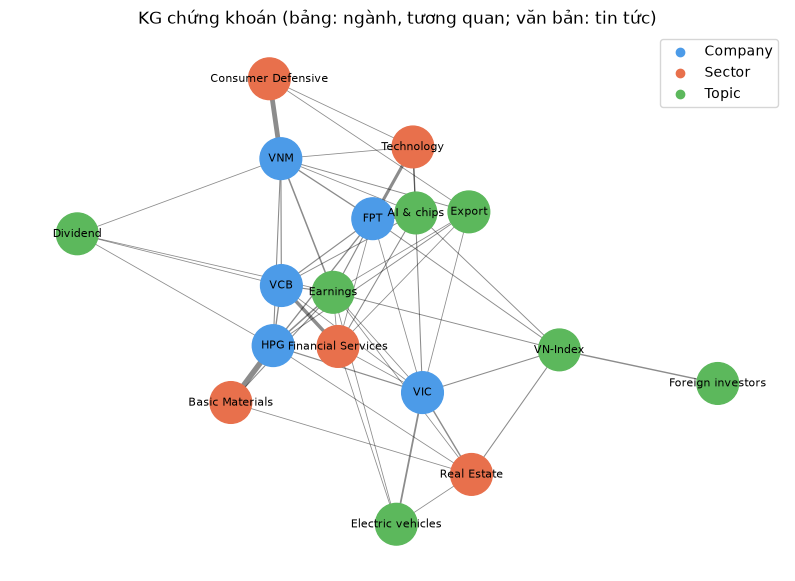

Chủ đề tin tức gắn với từng công ty:
  VNM [('Earnings', 7, 'in_news_with'), ('Export', 2, 'in_news_with'), ('AI & chips', 1, 'in_news_with')]
  FPT [('AI & chips', 46, 'in_news_with'), ('Earnings', 4, 'in_news_with'), ('VN-Index', 2, 'in_news_with')]
  VCB [('Earnings', 4, 'in_news_with'), ('AI & chips', 2, 'in_news_with'), ('Dividend', 1, 'in_news_with')]
  HPG [('Earnings', 7, 'in_news_with'), ('Export', 2, 'in_news_with'), ('Dividend', 1, 'in_news_with')]
  VIC [('Electric vehicles', 9, 'in_news_with'), ('VN-Index', 3, 'in_news_with'), ('Earnings', 1, 'in_news_with')]
Năm lợi suất cao nhất:
 asset  year   return
  FPT  2024 0.852196
  HPG  2020 1.156011
  VCB  2023 0.185429
  VIC  2025 7.364982
  VNM  2020 0.153360


In [11]:
G_stock = new_kg(STOCK_LEX)
# (1) từ bảng: ngành và tương quan
for t, sec in SECTOR.items():
    G_stock.add_edge(
        t,
        sec,
        rel="BELONGS_TO_SECTOR",
        weight=5,
        industry=info[t].get("industry"),
        source="table",
    )
for a, b in itertools.combinations(sp.columns, 2):
    c = float(s_corr.loc[a, b])
    if abs(c) >= 0.15:
        G_stock.add_edge(
            a, b, rel="CORRELATED_WITH", weight=10 * abs(c), corr=c, source="table"
        )
# (2) từ văn bản: đồng xuất hiện trong tin tức
stock_rel = make_rel(
    {
        ("Company", "Topic"): "in_news_with",
        ("Company", "Company"): "mentioned_with",
        ("Company", "Sector"): "related_to_sector",
        ("Sector", "Topic"): "sector_topic",
    }
)
add_cooccurrence(G_stock, s_news_docs, stock_rel)
G_stock.remove_nodes_from(
    [n for n, a in G_stock.nodes(data=True) if a["etype"] == "Year"]
)  # năm chỉ dùng để truy xuất
print("Nút:", G_stock.number_of_nodes(), "| cạnh:", G_stock.number_of_edges())
nx.write_graphml(G_stock, os.path.join(WORK_DIR, "kg_stocks.graphml"))
draw_entity_graph(
    G_stock,
    "KG chứng khoán (bảng: ngành, tương quan; văn bản: tin tức)",
    "kg_stocks",
    figsize=(10, 7),
)

print("Chủ đề tin tức gắn với từng công ty:")
for t in STOCKS:
    print(" ", t, top_links(G_stock, t, "Topic", 3))
best = s_stats.loc[
    s_stats.groupby("asset")["return"].idxmax(), ["asset", "year", "return"]
]
print("Năm lợi suất cao nhất:\n", best.to_string(index=False))

=== RAG thường ===
Thực thể trong câu hỏi: ['2021', 'Basic Materials', 'HPG'] | mở rộng KG: []
Trả lời: Tue, 13 Jan 2026: Hoa Phat sets record with steel sales topping 10 million tonnes in 2025, up 31% year on year (source: HoaPhat). Mon, 12 Oct 2026: Hoa Phat sold over 10.3 million tons of steel in the first nine months, a 39% increase compared to the same period last year. Fri, 14 Aug 2026: Hoa Phat starts 700,000-tpy steel mill in Long An to strengthen southern market presence (source: megaproject.com).
Nguồn: ['news:307', 'news:327', 'news:341'] 

=== GraphRAG ===
Thực thể trong câu hỏi: ['2021', 'Basic Materials', 'HPG'] | mở rộng KG: ['Earnings', 'FPT', 'VCB', 'VIC']
  KG: (Basic Materials) -[BELONGS_TO_SECTOR, w=40.0]-> (HPG)
  KG: (Basic Materials) -[sector_topic, w=3.0]-> (Earnings)
  KG: (Basic Materials) -[related, w=1.0]-> (Real Estate)
  KG: (HPG) -[BELONGS_TO_SECTOR, w=40.0]-> (Basic Materials)
  KG: (HPG) -[in_news_with, w=7.0]-> (Earnings)
  KG: (HPG) -[CORRELATED_WITH,

,RAG,GraphRAG
k,,
2,0.7,0.7
4,0.7,0.9
6,0.7,0.9


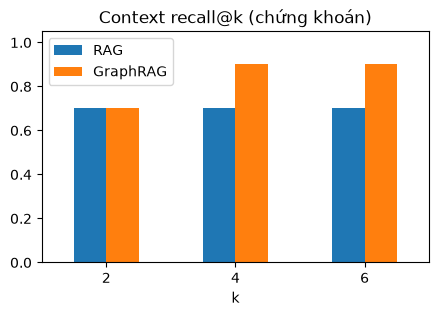

In [12]:
stock_rag = GraphRAG(
    stock_docs,
    STOCK_LEX,
    G_stock,
    Retriever([d["text"] for d in stock_docs]),
    hub_ratio=0.3,
)
compare(
    stock_rag,
    "How did the steel company Hoa Phat perform in 2021 "
    "and what is the recent news about it?",
)

STOCK_QA = [
    ("How did the steel company Hoa Phat perform in 2021?", [r"hpg", r"2021"]),
    ("How correlated are VCB and VIC returns?", [r"vcb", r"vic", r"correlation"]),
    (
        "What is FPT's sector and its volatility in 2024?",
        [r"fpt", r"technology", r"2024"],
    ),
    (
        "Which bank is in the dataset and how did it perform in 2023?",
        [r"vcb|bank", r"2023"],
    ),
    ("How did Vinamilk dairy perform in 2020?", [r"vnm|vinamilk", r"2020"]),
    (
        "Compare the technology company FPT and the bank VCB in 2022",
        [r"fpt", r"vcb", r"2022"],
    ),
    ("What recent news is there about Hoa Phat steel?", [r"hoa phat|hpg", r"steel"]),
    (
        "Is there news about FPT and artificial intelligence or chips?",
        [r"fpt", r"\bai\b|artificial|semiconductor|chip"],
    ),
    (
        "What is the latest news on Vietcombank profit?",
        [r"vietcombank|vcb", r"profit|earnings|revenue"],
    ),
    (
        "What news is there about Vingroup and electric vehicles?",
        [r"vingroup|vinfast|vic", r"electric|\bev\b|vinfast"],
    ),
]
res_stock = evaluate(stock_rag, STOCK_QA, "chứng khoán", "eval_stocks")

## 4.5.2 Bài 3: KB và RAG cho vàng

**Dữ liệu:**
- **Bảng:** giá vàng (GC=F) và các yếu tố ảnh hưởng: USD index (DX-Y.NYB), lợi suất TP Mỹ 10 năm (^TNX), bạc, dầu, S&P 500, VIX, Bitcoin.
- **Văn bản:** tin tức về vàng (Fed, lạm phát, ngân hàng trung ương, địa chính trị, ETF...).

KG kết hợp 3 nguồn quan hệ:
1. **Bảng →** `CORRELATED_WITH` giữa các tài sản (lợi suất tuần; với lợi suất trái phiếu và VIX dùng chênh lệch mức).
2. **Văn bản →** đồng xuất hiện trong tin: `influenced_by`, `co_moves_with`...
3. **Tri thức chuyên gia →** vài quan hệ nhân quả đã biết (nét đứt trên hình), ví dụ lợi suất thực tăng làm tăng chi phí cơ hội nắm giữ vàng.

Bảng: (2480, 8) 2020-01-01 -> 2026-10-15 | tin tức: 632


,year,start,last,return,vol,mdd
0,2020,1524.5,1895.1,0.243,0.217,-0.142
1,2021,1946.6,1828.6,-0.061,0.148,-0.141
2,2022,1800.1,1826.2,0.014,0.157,-0.202
3,2023,1846.1,2071.8,0.122,0.134,-0.109
4,2024,2073.4,2641.0,0.274,0.153,-0.082
5,2025,2669.0,4341.1,0.626,0.209,-0.092
6,2026,4329.6,4175.9,-0.035,0.296,-0.249


,corr với GOLD
USD,-0.43
US10Y,-0.25
VIX,-0.16
OIL,0.07
BTC,0.13
SP500,0.26
SILVER,0.79


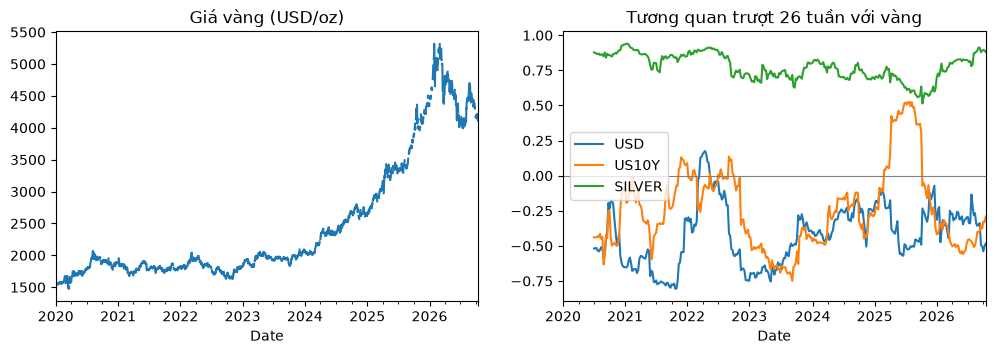

In [13]:
gm = pd.read_csv(
    os.path.join(DATA_DIR, "gold_market.csv"), parse_dates=[0], index_col=0
).sort_index()
gnews = pd.read_csv(os.path.join(DATA_DIR, "gold_news.csv"))
LEVEL = ("US10Y", "VIX")
LABEL = {
    "GOLD": "gold futures, USD/oz",
    "SILVER": "silver futures",
    "USD": "US dollar index",
    "US10Y": "US 10-year Treasury yield, %",
    "OIL": "WTI crude oil",
    "SP500": "S&P 500 index",
    "VIX": "VIX volatility index",
    "BTC": "Bitcoin, USD",
}
print(
    "Bảng:",
    gm.shape,
    gm.index.min().date(),
    "->",
    gm.index.max().date(),
    "| tin tức:",
    len(gnews),
)

g_stats = yearly_stats(gm, LEVEL)
display(
    g_stats[g_stats.asset == "GOLD"][
        ["year", "start", "last", "return", "vol", "mdd"]
    ].round(3)
)
g_chg = weekly_changes(gm, LEVEL)
g_corr = g_chg.corr()
display(g_corr["GOLD"].drop("GOLD").sort_values().round(2).to_frame("corr với GOLD"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
gm["GOLD"].plot(ax=ax[0], title="Giá vàng (USD/oz)")
for c in ["USD", "US10Y", "SILVER"]:
    g_chg["GOLD"].rolling(26).corr(g_chg[c]).plot(ax=ax[1], label=c)
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].legend()
ax[1].set_title("Tương quan trượt 26 tuần với vàng")
save_show("gold_price_corr")

In [14]:
GOLD_LEX = {
    "GOLD": ["Asset", r"\bgold\b|bullion|\bxau"],
    "SILVER": ["Asset", r"silver"],
    "USD": ["Asset", r"dollar|\busd\b|\bdxy\b|greenback"],
    "US10Y": ["Asset", r"treasury|treasuries|bond yield|\byields?\b|us10y"],
    "OIL": ["Asset", r"\boil\b|crude|brent|\bwti\b"],
    "SP500": ["Asset", r"s&p|sp500|wall street|equities|stock market"],
    "VIX": ["Asset", r"\bvix\b|volatility index"],
    "BTC": ["Asset", r"bitcoin|crypto|\bbtc\b"],
    "Fed": [
        "Driver",
        r"\bfed\b|federal reserve|powell|fomc|rate cuts?|rate hikes?|interest rates?",
    ],
    "Inflation": ["Driver", r"inflation|\bcpi\b"],
    "Central banks": ["Driver", r"central banks?|pboc|reserve bank|\brbi\b"],
    "Geopolitics": [
        "Driver",
        r"\bwar\b|geopolit|tensions?|conflict|sanction|tariff"
        r"|middle east|ukraine|israel|iran",
    ],
    "Recession": ["Driver", r"recession|slowdown|economic uncertainty"],
    "ETF flows": ["Driver", r"\betfs?\b|\bgld\b|spdr|inflows?|outflows?"],
    "China": ["Region", r"china|chinese"],
    "India": ["Region", r"india|indian"],
    "Record high": ["Theme", r"record|all-time high|new high"],
    "Safe haven": ["Theme", r"safe[- ]haven|\bhaven\b"],
}
for y in sorted(g_stats.year.unique()):
    GOLD_LEX[str(y)] = ["Year", rf"\b{y}\b"]
gold_rx = compile_lexicon(GOLD_LEX)

gold_docs = [
    {
        "text": stats_to_text(r, LABEL[r.asset], LEVEL),
        "source": f"stats:{r.asset}:{r.year}",
    }
    for _, r in g_stats.iterrows()
]
gold_docs += [
    {
        "text": corr_text(f"{a} ({LABEL[a]})", f"{b} ({LABEL[b]})", g_corr.loc[a, b]),
        "source": f"corr:{a}-{b}",
    }
    for a, b in itertools.combinations(gm.columns, 2)
]
for d in gold_docs:
    d["entities"] = extract_entities(d["text"], gold_rx)
g_news_docs = news_docs(gnews, gold_rx)
gold_docs += g_news_docs
print(
    len(gold_docs),
    "tài liệu:",
    collections.Counter(d["source"].split(":")[0] for d in gold_docs),
)
print(
    "Thực thể phổ biến trong tin:",
    collections.Counter(e for d in g_news_docs for e in d["entities"]).most_common(8),
)

716 tài liệu: Counter({'news': 632, 'stats': 56, 'corr': 28})
Thực thể phổ biến trong tin: [('GOLD', 609), ('Inflation', 117), ('USD', 99), ('Fed', 99), ('China', 91), ('Central banks', 89), ('ETF flows', 86), ('Geopolitics', 75)]


Nút: 18 | cạnh: 99 | nguồn cạnh: Counter({'text': 87, 'table': 12})


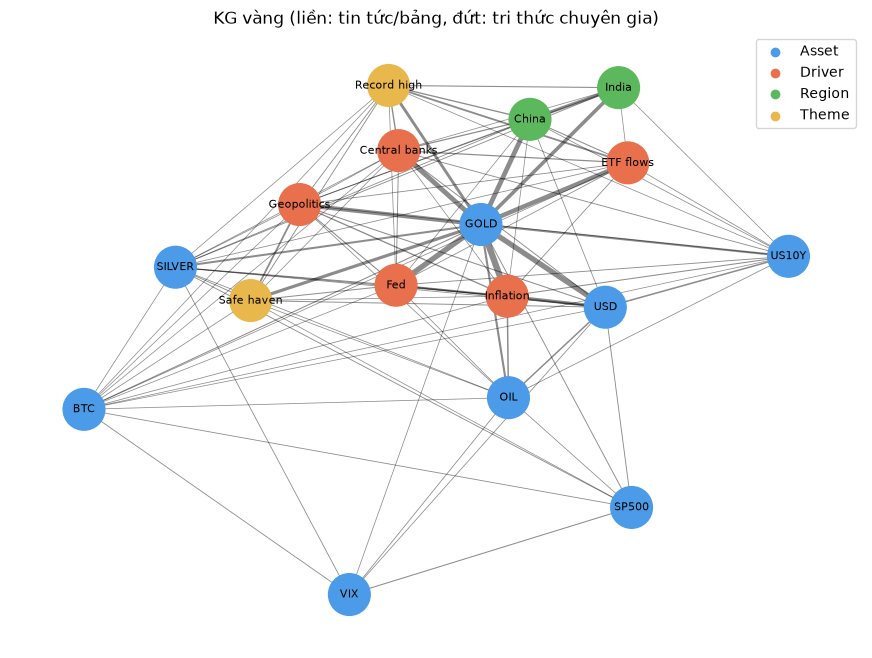

Yếu tố gắn với vàng mạnh nhất: [('Inflation', 117, 'hedged_by'), ('Fed', 99, 'influenced_by'), ('Central banks', 87, 'accumulate'), ('ETF flows', 80, 'investment_demand_for'), ('Geopolitics', 73, 'influenced_by')]


In [15]:
G_gold = new_kg(GOLD_LEX)
# (1) từ văn bản: đồng xuất hiện trong tin
gold_rel = make_rel(
    {
        ("Asset", "Driver"): "influenced_by",
        ("Asset", "Asset"): "co_moves_with",
        ("Asset", "Region"): "demand_from",
        ("Asset", "Theme"): "described_as",
        ("Driver", "Driver"): "linked_with",
        ("Driver", "Theme"): "drives",
    }
)
add_cooccurrence(G_gold, g_news_docs, gold_rel)
# (2) từ bảng: tương quan (cạnh tin tức đã có thì chỉ gắn thêm thuộc tính corr)
for a, b in itertools.combinations(gm.columns, 2):
    c = float(g_corr.loc[a, b])
    if abs(c) < 0.15:
        continue
    if G_gold.has_edge(a, b):
        G_gold[a][b]["corr"] = c
    else:
        G_gold.add_edge(
            a, b, rel="CORRELATED_WITH", weight=10 * abs(c), corr=c, source="table"
        )
# (3) tri thức chuyên gia
DOMAIN = [
    ("Fed", "US10Y", "sets_policy_rate_for"),
    ("US10Y", "GOLD", "opportunity_cost_of"),
    ("USD", "GOLD", "prices"),
    ("Inflation", "GOLD", "hedged_by"),
    ("Geopolitics", "Safe haven", "raises_demand_for"),
    ("Safe haven", "GOLD", "role_of"),
    ("Central banks", "GOLD", "accumulate"),
    ("ETF flows", "GOLD", "investment_demand_for"),
    ("Fed", "USD", "affects"),
]
for a, b, r in DOMAIN:
    if G_gold.has_edge(a, b):
        G_gold[a][b].update(rel=r, domain=True)
    else:
        G_gold.add_edge(a, b, rel=r, weight=3, source="domain")
G_gold.remove_nodes_from(
    [n for n, a in G_gold.nodes(data=True) if a["etype"] == "Year"]
)
print(
    "Nút:",
    G_gold.number_of_nodes(),
    "| cạnh:",
    G_gold.number_of_edges(),
    "| nguồn cạnh:",
    collections.Counter(a.get("source") for _, _, a in G_gold.edges(data=True)),
)
nx.write_graphml(G_gold, os.path.join(WORK_DIR, "kg_gold.graphml"))
draw_entity_graph(
    G_gold,
    "KG vàng (liền: tin tức/bảng, đứt: tri thức chuyên gia)",
    "kg_gold",
    figsize=(11, 8),
)
print("Yếu tố gắn với vàng mạnh nhất:", top_links(G_gold, "GOLD", "Driver", 5))

Hub: {'GOLD'}
=== RAG thường ===
Thực thể trong câu hỏi: ['Fed', 'GOLD', 'USD'] | mở rộng KG: []
Trả lời: Wed, 07 Oct 2026: Gold Prices Fall as Dollar Strengthens Ahead of Federal Reserve Minutes (source: Yahoo Finance). Thu, 08 Oct 2026: Gold Prices Stabilise After Two-Month Low as Investors Assess Federal Reserve Rate Outlook (source: Yahoo Finance). Wed, 14 Oct 2026: Gold and silver prices decline as hotter-than-expected CPI data reignites pressure on the Federal Reserve to raise interest rates (source: Moomoo).
Nguồn: ['news:106', 'news:111', 'news:143'] 

=== GraphRAG ===
Thực thể trong câu hỏi: ['Fed', 'GOLD', 'USD'] | mở rộng KG: ['Inflation', 'Central banks', 'Geopolitics', 'China']
  KG: (Fed) -[influenced_by, w=99.0]-> (GOLD)
  KG: (Fed) -[linked_with, w=25.0]-> (Inflation)
  KG: (Fed) -[affects, w=14.0]-> (USD)
  KG: (Fed) -[linked_with, w=8.0]-> (Geopolitics)
  KG: (GOLD) -[hedged_by, w=117.0]-> (Inflation)
  KG: (GOLD) -[influenced_by, w=99.0]-> (Fed)
Trả lời: Wed, 07 Oct 

,RAG,GraphRAG
k,,
2,0.9,0.9
4,0.9,0.9
6,1.0,0.9


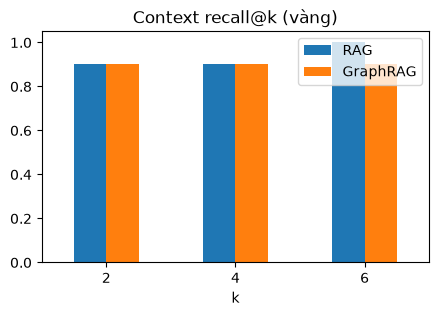

In [16]:
gold_rag = GraphRAG(
    gold_docs,
    GOLD_LEX,
    G_gold,
    Retriever([d["text"] for d in gold_docs]),
    hub_ratio=0.3,
)
print("Hub:", gold_rag.hubs)
compare(gold_rag, "How do Federal Reserve rate cuts and the dollar affect gold prices?")

GOLD_QA = [
    (
        "How did gold perform in 2025 and what was its drawdown?",
        [r"gold", r"2025", r"drawdown"],
    ),
    (
        "Is gold correlated with the US dollar?",
        [r"gold", r"usd|dollar", r"correlation"],
    ),
    ("How do Treasury yields relate to gold?", [r"gold", r"us10y|yield|treasury"]),
    ("Are central banks buying gold?", [r"central bank", r"gold"]),
    (
        "Why is gold seen as a safe haven during geopolitical tensions?",
        [r"gold", r"haven|war|tension|geopolit|tariff"],
    ),
    (
        "How do Fed rate cuts affect gold prices?",
        [r"gold", r"fed|federal reserve|rate cut"],
    ),
    ("Compare gold and silver returns in 2024", [r"gold", r"silver", r"2024"]),
    ("What is the news on gold ETF inflows?", [r"gold", r"etf|inflow"]),
    (
        "What is the correlation between gold and bitcoin?",
        [r"gold", r"btc|bitcoin", r"correlation"],
    ),
    ("How does gold demand from China and India look?", [r"gold", r"china|india"]),
]
res_gold = evaluate(gold_rag, GOLD_QA, "vàng", "eval_gold")

In [17]:
# (Tùy chọn) sinh câu trả lời bằng LLM nhỏ thay cho trích xuất (nên bật GPU).
USE_LLM = False
if USE_LLM:
    from transformers import pipeline

    gen = pipeline("text2text-generation", model="google/flan-t5-large")

    def llm_answer(rag, q, k=4, mode="graph"):
        res = rag.answer(q, k, mode)
        ctx = " ".join(rag.docs[h["i"]]["text"] for h in res["hits"])[:2500]
        facts = "; ".join(res["kg_facts"][:6])
        prompt = (
            f"Answer using the context and facts.\nFacts: {facts}\n"
            f"Context: {ctx}\nQuestion: {q}\nAnswer:"
        )
        return gen(prompt, max_new_tokens=160)[0]["generated_text"], res["sources"]

    print(llm_answer(gold_rag, "How do Fed rate cuts affect gold prices?"))

In [18]:
summary = pd.concat(
    {"Tiểu đường": res_diab, "Chứng khoán": res_stock, "Vàng": res_gold}, axis=1
)
display(summary)

Tiểu đường          Chứng khoán          Vàng         
         RAG GraphRAG         RAG GraphRAG  RAG GraphRAG
k                                                       
2      0.417    0.750         0.7      0.7  0.9      0.9
4      0.667    0.833         0.7      0.9  0.9      0.9
6      0.667    0.833         0.7      0.9  1.0      0.9

In [19]:
# Ghi số liệu chính ra results/summary.json (báo cáo đọc số liệu từ file này)
def _ev(r):
    return {
        str(k): {"RAG": float(r.loc[k, "RAG"]), "GraphRAG": float(r.loc[k, "GraphRAG"])}
        for k in r.index
    }


gold_rows = g_stats[g_stats.asset == "GOLD"]
RESULTS = {
    "retriever": diab_rag.ret.mode,
    "eval": {
        "diabetes": _ev(res_diab),
        "stocks": _ev(res_stock),
        "gold": _ev(res_gold),
    },
    "n_questions": {
        "diabetes": len(DIAB_QA),
        "stocks": len(STOCK_QA),
        "gold": len(GOLD_QA),
    },
    "diabetes": {
        "papers": len(papers),
        "chunks": len(diab_docs),
        "ent_per_chunk": float(np.mean([len(d["entities"]) for d in diab_docs])),
        "nodes": G_diab.number_of_nodes(),
        "edges": G_diab.number_of_edges(),
        "entities": len(DIAB_LEX),
    },
    "stocks": {
        "docs": len(stock_docs),
        "news": len(s_news_docs),
        "rows": len(sp),
        "start": str(sp.index.min().date()),
        "end": str(sp.index.max().date()),
        "nodes": G_stock.number_of_nodes(),
        "edges": G_stock.number_of_edges(),
        "best_year": {
            r.asset: [int(r.year), float(r["return"])] for _, r in best.iterrows()
        },
    },
    "gold": {
        "docs": len(gold_docs),
        "news": len(g_news_docs),
        "rows": len(gm),
        "nodes": G_gold.number_of_nodes(),
        "edges": G_gold.number_of_edges(),
        "edge_sources": dict(
            collections.Counter(a.get("source") for _, _, a in G_gold.edges(data=True))
        ),
        "corr_gold": {k: float(v) for k, v in g_corr["GOLD"].drop("GOLD").items()},
        "gold_return": {
            int(r.year): float(r["return"]) for _, r in gold_rows.iterrows()
        },
    },
}
os.makedirs(os.path.join(WORK_DIR, "results"), exist_ok=True)
with open(
    os.path.join(WORK_DIR, "results", "summary.json"), "w", encoding="utf-8"
) as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2)
print(json.dumps(RESULTS["eval"], indent=1))

{
 "diabetes": {
  "2": {
   "RAG": 0.417,
   "GraphRAG": 0.75
  },
  "4": {
   "RAG": 0.667,
   "GraphRAG": 0.833
  },
  "6": {
   "RAG": 0.667,
   "GraphRAG": 0.833
  }
 },
 "stocks": {
  "2": {
   "RAG": 0.7,
   "GraphRAG": 0.7
  },
  "4": {
   "RAG": 0.7,
   "GraphRAG": 0.9
  },
  "6": {
   "RAG": 0.7,
   "GraphRAG": 0.9
  }
 },
 "gold": {
  "2": {
   "RAG": 0.9,
   "GraphRAG": 0.9
  },
  "4": {
   "RAG": 0.9,
   "GraphRAG": 0.9
  },
  "6": {
   "RAG": 1.0,
   "GraphRAG": 0.9
  }
 }
}


## 4.6 Deploy

1. **Trong Kaggle:** giao diện **Gradio** với 3 miền (`share=True` tạo link công khai tạm thời).
2. **Đóng gói** thư mục `deploy/` (KB + KG + từ điển dạng JSON, `ragkg_core.py`, `app.py`, `requirements.txt`) để đưa lên Hugging Face Spaces hoặc server (`python app.py`). Bản deploy dùng TF-IDF cho nhẹ, không cần GPU.

In [20]:
DEPLOY = os.path.join(WORK_DIR, "deploy")
os.makedirs(DEPLOY, exist_ok=True)
for name, docs, lex, G in [
    ("diabetes.json", diab_docs, DIAB_LEX, G_diab),
    ("stocks.json", stock_docs, STOCK_LEX, G_stock),
    ("gold.json", gold_docs, GOLD_LEX, G_gold),
]:
    json.dump(
        {"docs": docs, "lexicon": lex, "graph": graph_to_dict(G)},
        open(os.path.join(DEPLOY, name), "w", encoding="utf-8"),
        ensure_ascii=False,
    )
shutil.copy(
    os.path.join(WORK_DIR, "ragkg_core.py"), os.path.join(DEPLOY, "ragkg_core.py")
)

APP = """import json, os
import gradio as gr
from ragkg_core import GraphRAG, Retriever, graph_from_dict

HERE = os.path.dirname(os.path.abspath(__file__))
EXAMPLES = {"Tiểu đường": "Which drugs are studied for diabetic kidney disease?",
            "Chứng khoán": "How did Hoa Phat perform in 2021?",
            "Vàng": "How do Fed rate cuts affect gold prices?"}
FILES = [("Tiểu đường", "diabetes.json"), ("Chứng khoán", "stocks.json"),
         ("Vàng", "gold.json")]
SYSTEMS = {}
for name, f in FILES:
    d = json.load(open(os.path.join(HERE, f), encoding="utf-8"))
    retr = Retriever([x["text"] for x in d["docs"]], use_embeddings=False)
    G = graph_from_dict(d["graph"])
    SYSTEMS[name] = GraphRAG(d["docs"], d["lexicon"], G, retr)


def ask(domain, question, mode, k):
    m = "graph" if mode == "GraphRAG" else "rag"
    r = SYSTEMS[domain].answer(question, k=int(k), mode=m)
    facts = "\\n".join(r["kg_facts"]) or "(RAG thường: không dùng KG)"
    expand = (", ".join(r["query_entities"]) + " -> "
              + ", ".join(r["graph_expansion"]))
    return r["answer"], ", ".join(r["sources"]), expand, facts


SLUG = {"diabetes": "Tiểu đường", "stocks": "Chứng khoán", "gold": "Vàng"}


def from_url(request: gr.Request):
    # ?domain=gold&q=...&mode=rag: mở sẵn câu hỏi và trả lời ngay khi tải trang
    p = dict(request.query_params) if request else {}
    d = SLUG.get(p.get("domain"), "Tiểu đường")
    q = p.get("q") or EXAMPLES[d]
    m = "RAG" if p.get("mode") == "rag" else "GraphRAG"
    return (d, q, m, *ask(d, q, m, 4))


with gr.Blocks(title="KG + RAG") as demo:
    gr.Markdown("# Knowledge Graph + RAG: tiểu đường, chứng khoán, vàng\\n"
                "Hỏi bằng tiếng Anh (kho dữ liệu là tiếng Anh).")
    domain = gr.Dropdown(list(SYSTEMS), value="Tiểu đường", label="Bài")
    question = gr.Textbox(label="Câu hỏi", value=EXAMPLES["Tiểu đường"])
    domain.input(lambda d: EXAMPLES[d], domain, question)
    with gr.Row():
        mode = gr.Radio(["GraphRAG", "RAG"], value="GraphRAG", label="Chế độ")
        k = gr.Slider(1, 8, value=4, step=1, label="top-k")
    btn = gr.Button("Hỏi")
    ans = gr.Textbox(label="Câu trả lời", lines=6)
    src = gr.Textbox(label="Nguồn")
    ent = gr.Textbox(label="Thực thể -> mở rộng KG")
    facts = gr.Textbox(label="Facts từ KG", lines=5)
    btn.click(ask, [domain, question, mode, k], [ans, src, ent, facts])
    demo.load(from_url, None, [domain, question, mode, ans, src, ent, facts])


if __name__ == "__main__":
    demo.launch()
"""
open(os.path.join(DEPLOY, "app.py"), "w", encoding="utf-8").write(APP)
open(os.path.join(DEPLOY, "requirements.txt"), "w").write(
    "gradio\nnetworkx\nscikit-learn\nnumpy\n"
)
print(sorted(os.listdir(DEPLOY)))

['__pycache__', 'app.py', 'diabetes.json', 'gold.json', 'ragkg_core.py', 'requirements.txt', 'stocks.json']


In [21]:
# Chạy thử app đóng gói với cả 3 bài, rồi mở giao diện Gradio
import importlib.util

sys.path.insert(0, DEPLOY)
spec = importlib.util.spec_from_file_location(
    "deploy_app", os.path.join(DEPLOY, "app.py")
)
app = importlib.util.module_from_spec(spec)
spec.loader.exec_module(app)
for dom, q in app.EXAMPLES.items():
    out = app.ask(dom, q, "GraphRAG", 4)
    print(f"[{dom}] {q}\n  -> {out[0][:180]}\n  nguồn: {out[1]}")

if not os.environ.get("LOCAL_DATA"):  # trên Kaggle: mở giao diện, tạo link public
    app.demo.launch(share=True, prevent_thread_lock=True)

[Tiểu đường] Which drugs are studied for diabetic kidney disease?
  -> MicroRNAs: new biomarkers and promising therapeutic targets for diabetic kidney disease.. Diabetic kidney disease (DKD) is a chronic complication of diabetes mellitus associated wi
  nguồn: PMID:30742700, PMID:37737333
[Chứng khoán] How did Hoa Phat perform in 2021?
  -> HPG (Hoa Phat Group Joint Stock Company, sector Basic Materials) in 2021: price return +52.7%, annualized volatility 34.7%, maximum drawdown -22.5%, last price 23633.99. Thu, 17 Ju
  nguồn: news:358, news:370, stats:HPG:2021
[Vàng] How do Fed rate cuts affect gold prices?
  -> Wed, 14 Oct 2026: Rising Government Debt Extends Gold’s Appeal Beyond Fed Rate Cuts (source: Crux Investor). Tue, 22 Sep 2026: Gold Prices Fall as Stronger Dollar and Fed Rate Expe
  nguồn: news:142, news:178, news:54


## Kết luận

| | Tiểu đường | Chứng khoán | Vàng |
|---|---|---|---|
| Dữ liệu | Văn bản (PubMed) + nhãn MeSH | Bảng giá + hồ sơ công ty + tin tức | Bảng giá vàng và các yếu tố + tin tức |
| Thực thể | Thuốc, biến chứng, bệnh | Công ty, ngành, chủ đề tin | Tài sản, yếu tố vĩ mô, khu vực |
| Quan hệ KG | Đồng xuất hiện trong văn bản | Ngành, tương quan (bảng) + tin tức | Tương quan (bảng) + tin tức + tri thức chuyên gia |

**Nhận xét**
- Xem bảng tổng hợp *context recall* ở trên để biết con số thực tế của lần chạy (có thể thay đổi giữa các lần vì tin tức và PubMed được tải mới).
- GraphRAG có lợi nhất khi câu hỏi chứa nhiều thực thể và tài liệu liên quan nằm rải rác (multi-hop). Khi câu hỏi đã chứa từ khóa rất đặc trưng (mã cổ phiếu, năm), truy xuất hybrid thường đã đủ.
- Bảng phải được chuyển thành câu văn mới đưa vào RAG được; đồng thời bảng cung cấp quan hệ định lượng (tương quan) mà văn bản không có.
- NER bằng từ điển: chính xác nhưng độ phủ thấp; hướng mở rộng là dùng LLM/scispaCy để trích thực thể và quan hệ.
- Tin tức chỉ có tiêu đề (Google News RSS); muốn sâu hơn cần crawl nội dung bài.
- Dữ liệu và câu hỏi bằng tiếng Anh; muốn hỏi tiếng Việt cần embedding đa ngữ và dữ liệu tiếng Việt.
- Kết quả chứng khoán và vàng chỉ minh họa kỹ thuật, không phải lời khuyên đầu tư.